In [ ]:
# ---------------------------------------------------------------------------
# Import Libraries and Reproducibility setup
# ---------------------------------------------------------------------------

import sys
import os 
import scipy
import sklearn
import matplotlib
import matplotlib.pyplot as plt
import warnings
import numpy as np
from scipy.stats import rankdata, norm, spearmanr
from scipy.spatial.distance import pdist
from scipy.optimize import minimize
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, ConstantKernel as C

SEED = 42                                                 # Random seed 
rng_global = np.random.default_rng(SEED)

print("=" * 70)
print("Software and Libraries used")
print("=" * 70)
print(f"  python      : {sys.version.split()[0]}")
print(f"  numpy       : {np.__version__}")
print(f"  scipy       : {scipy.__version__}")
print(f"  scikit-learn: {sklearn.__version__}")
print(f"  matplotlib  : {matplotlib.__version__}")
print(f"  SEED        : {SEED}")
print()

Software and Libraries used
  python      : 3.13.9
  numpy       : 2.3.5
  scipy       : 1.16.3
  scikit-learn: 1.9.0
  matplotlib  : 3.11.1
  SEED        : 42



In [ ]:
# ---------------------------------------------------------------------
# Load Data
# ---------------------------------------------------------------------

X = np.load('..\Function_1_Data\Week_10_Data/F1_Week_10_inputs.npy')
y = np.load('..\Function_1_Data\Week_10_Data/F1_Week_10_outputs.npy')

n = len(y)
inc = int(np.argmax(y))

In [ ]:
# ---------------------------------------------------------------------
# Re-apply rank-based copula and asignh transforms to all 19 points
# ---------------------------------------------------------------------
def copula(y):
    return norm.ppf((rankdata(y) - 0.5) / len(y))

def asinh_target(y, s):
    return np.arcsinh(y / s)

In [ ]:
# ---------------------------------------------------------------------
# Refit Matern 5/2 ARD GP on all 19 points 
# ---------------------------------------------------------------------
def fit_gp(X, t, lb=0.02, amp_bounds=(1e-2, 1e2)):
    init = np.array([np.median(pdist(X[:, [j]])) for j in range(X.shape[1])])
    k = C(1.0, amp_bounds) * Matern(length_scale=init, length_scale_bounds=(lb, 2.0), nu=2.5)
    return GaussianProcessRegressor(kernel=k, alpha=1e-6, n_restarts_optimizer=15,
                                    random_state=SEED).fit(X, t)


def loo(gp, X, t):
    """Leave-one-out with hyperparameters held at the full-data fit."""
    mu, sd = np.empty(len(t)), np.empty(len(t))
    for i in range(len(t)):
        m = np.arange(len(t)) != i
        g = GaussianProcessRegressor(kernel=gp.kernel_, optimizer=None, alpha=1e-6).fit(X[m], t[m])
        a, b = g.predict(X[i:i + 1], return_std=True)
        mu[i], sd[i] = a[0], b[0]
    return mu, sd


def ei(mu, sd, fb, xi=0.0):
    sd = np.maximum(sd, 1e-12)
    z = (mu - fb - xi) / sd
    return (mu - fb - xi) * norm.cdf(z) + sd * norm.pdf(z)


def grid(lo, hi, m=301):
    t1, t2 = np.linspace(lo[0], hi[0], m), np.linspace(lo[1], hi[1], m)
    return np.array(np.meshgrid(t1, t2)).reshape(2, -1).T


def report(name, gp, t):
    ls = gp.kernel_.k2.length_scale
    mu, sd = loo(gp, X, t)
    print(f"  kernel            : {gp.kernel_}")
    print(f"  length-scales     : [{ls[0]:.4f}, {ls[1]:.4f}]   LML={gp.log_marginal_likelihood_value_:.3f}")
    print(f"  LOO RMSE / std(t) : {np.sqrt(np.mean((t - mu) ** 2)) / t.std():.3f}   (1.0 = no better than the mean)")
    print(f"  LOO Spearman      : {spearmanr(t, mu)[0]:.3f}")
    print(f"  LOO pred. at incumbent: {mu[inc]:.3f} +/- {sd[inc]:.3f}  (actual {t[inc]:.3f})")

G_full = grid([0, 0], [1, 1])

In [ ]:

# ----------------------------------------------------------------- 
# Original
# ----------------------------------------------------------------- 
print("=" * 72)
print("A. ORIGINAL: rank/copula target")
print("=" * 72)
t_c = copula(y)
for lb in [0.02, 0.01, 0.005]:
    g = fit_gp(X, t_c, lb)
    print(f"  ls lower bound {lb:<6}: ls={np.round(g.kernel_.k2.length_scale, 4)}  LML={g.log_marginal_likelihood_value_:.3f}")
gp_c = fit_gp(X, t_c)
report("copula", gp_c, t_c)
mu, sd = gp_c.predict(G_full, return_std=True)
e = ei(mu, sd, t_c.max(), 0.01)
print(f"  EI(xi=0.01) grid argmax : {np.round(G_full[e.argmax()], 4)}  EI={e.max():.4f}")
print(f"  share of domain with sigma > 90% of prior sd : {np.mean(sd > 0.9 * np.sqrt(gp_c.kernel_.k1.constant_value)):.1%}")
for beta in [1.0, 4.0, 16.0]:
    u = mu + np.sqrt(beta) * sd
    print(f"  UCB(beta={beta:<4}) grid argmax: {np.round(G_full[u.argmax()], 4)}  "
          f"share of domain within 5% of max: {np.mean(u > u.max() - 0.05 * abs(u.max())):.1%}")

# original optimiser: how many of 25 random L-BFGS-B starts reach the grid max?
rng = np.random.default_rng(SEED)
fb = t_c.max()
def neg(x):
    m_, s_ = gp_c.predict(x.reshape(1, -1), return_std=True)
    return -ei(m_, s_, fb, 0.01)[0]
vals = [-minimize(neg, x0, bounds=[(0, 1), (0, 1)], method="L-BFGS-B").fun
        for x0 in rng.uniform(0, 1, (25, 2))]
print(f"  original optimiser: {np.sum(np.array(vals) > 0.9 * e.max())}/25 starts reach >=90% of grid max "
      f"(best {max(vals):.4f} vs grid {e.max():.4f})")
print()


A. ORIGINAL: rank/copula target
  ls lower bound 0.02  : ls=[0.0303 0.02  ]  LML=-24.405


c:\Users\Ilias\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 1 of parameter k2__length_scale is close to the specified lower bound 0.02. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


  ls lower bound 0.01  : ls=[0.0307 0.0172]  LML=-24.386
  ls lower bound 0.005 : ls=[0.1773 0.005 ]  LML=-24.162


c:\Users\Ilias\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 1 of parameter k2__length_scale is close to the specified lower bound 0.005. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
c:\Users\Ilias\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 1 of parameter k2__length_scale is close to the specified lower bound 0.02. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


  kernel            : 0.902**2 * Matern(length_scale=[0.0303, 0.02], nu=2.5)
  length-scales     : [0.0303, 0.0200]   LML=-24.405
  LOO RMSE / std(t) : 0.842   (1.0 = no better than the mean)
  LOO Spearman      : 0.465
  LOO pred. at incumbent: 0.965 +/- 0.564  (actual 1.938)
  EI(xi=0.01) grid argmax : [0.5533 0.5467]  EI=0.0761
  share of domain with sigma > 90% of prior sd : 95.4%
  UCB(beta=1.0 ) grid argmax: [0.5533 0.5467]  share of domain within 5% of max: 0.0%
  UCB(beta=4.0 ) grid argmax: [0.5533 0.5533]  share of domain within 5% of max: 0.0%
  UCB(beta=16.0) grid argmax: [0.5567 0.56  ]  share of domain within 5% of max: 0.1%
  original optimiser: 0/25 starts reach >=90% of grid max (best 0.0086 vs grid 0.0761)



In [ ]:

# ------------------------------------------------------------------ 
# Revised
# ------------------------------------------------------------------

print("=" * 72)
print("B. REVISED: asinh(y/s) target, grid acquisition")
print("=" * 72)
lo, hi = np.array([0.45, 0.45]), np.array([0.75, 0.75])
G_loc = grid(lo, hi)
proposals = []
for s in [1e-10, 1e-12, 1e-14]:
    t = asinh_target(y, s)
    gp = fit_gp(X, t, amp_bounds=(1e-2, 1e4))
    print(f"--- s = {s:g}   target range [{t.min():.2f}, {t.max():.2f}]")
    report(f"asinh s={s:g}", gp, t)
    for label, G in [("full domain", G_full), ("local box  ", G_loc)]:
        mu, sd = gp.predict(G, return_std=True)
        e = ei(mu, sd, t.max())
        x = G[e.argmax()]
        print(f"  EI argmax ({label}): {np.round(x, 4)}  EI={e.max():.4f}  "
              f"mu={mu[e.argmax()]:.3f} sd={sd[e.argmax()]:.3f}")
        proposals.append(x)
        pm = G[mu.argmax()]
    print(f"  posterior-mean argmax (local box): {np.round(pm, 4)}")
    print()

proposals = np.array(proposals)
print("=" * 72)
print("C. SUMMARY OF REVISED PROPOSALS")
print("=" * 72)
print(np.round(proposals, 6))
print(f"  spread (max-min): {np.round(proposals.max(0) - proposals.min(0), 4)}")
print(f"  incumbent: {X[inc]}  y={y[inc]:.3e}")


B. REVISED: asinh(y/s) target, grid acquisition
--- s = 1e-10   target range [-18.09, 2.14]
  kernel            : 5.02**2 * Matern(length_scale=[0.02, 2], nu=2.5)
  length-scales     : [0.0200, 2.0000]   LML=-54.580
  LOO RMSE / std(t) : 0.619   (1.0 = no better than the mean)
  LOO Spearman      : 0.605
  LOO pred. at incumbent: 0.015 +/- 0.972  (actual 2.136)


c:\Users\Ilias\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 0.02. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
c:\Users\Ilias\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k2__length_scale is close to the specified upper bound 2.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


  EI argmax (full domain): [0.56   0.4467]  EI=1.9495  mu=4.051 sd=1.255
  EI argmax (local box  ): [0.56 0.45]  EI=1.9495  mu=4.052 sd=1.251
  posterior-mean argmax (local box): [0.559 0.516]



c:\Users\Ilias\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 1 of parameter k2__length_scale is close to the specified lower bound 0.02. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


--- s = 1e-12   target range [-22.70, 6.73]
  kernel            : 6.91**2 * Matern(length_scale=[0.0211, 0.02], nu=2.5)
  length-scales     : [0.0211, 0.0200]   LML=-63.338
  LOO RMSE / std(t) : 1.033   (1.0 = no better than the mean)
  LOO Spearman      : 0.177
  LOO pred. at incumbent: 0.613 +/- 5.211  (actual 6.728)
  EI argmax (full domain): [0.56 0.55]  EI=1.3094  mu=5.595 sd=4.561
  EI argmax (local box  ): [0.559 0.551]  EI=1.3096  mu=5.507 sd=4.654
  posterior-mean argmax (local box): [0.555 0.542]

--- s = 1e-14   target range [-27.30, 11.33]
  kernel            : 8.75**2 * Matern(length_scale=[0.0247, 0.0213], nu=2.5)
  length-scales     : [0.0247, 0.0213]   LML=-67.705
  LOO RMSE / std(t) : 0.975   (1.0 = no better than the mean)
  LOO Spearman      : 0.377
  LOO pred. at incumbent: 3.615 +/- 6.068  (actual 11.333)
  EI argmax (full domain): [0.5567 0.55  ]  EI=1.2466  mu=9.615 sd=4.984
  EI argmax (local box  ): [0.556 0.551]  EI=1.2512  mu=9.360 sd=5.242
  posterior-mean a

In [10]:
idx = np.arange(1, n + 1)
SURFACE, INK, INK2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e6e5e1"
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "DejaVu Sans", "font.size": 10, "text.color": INK,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

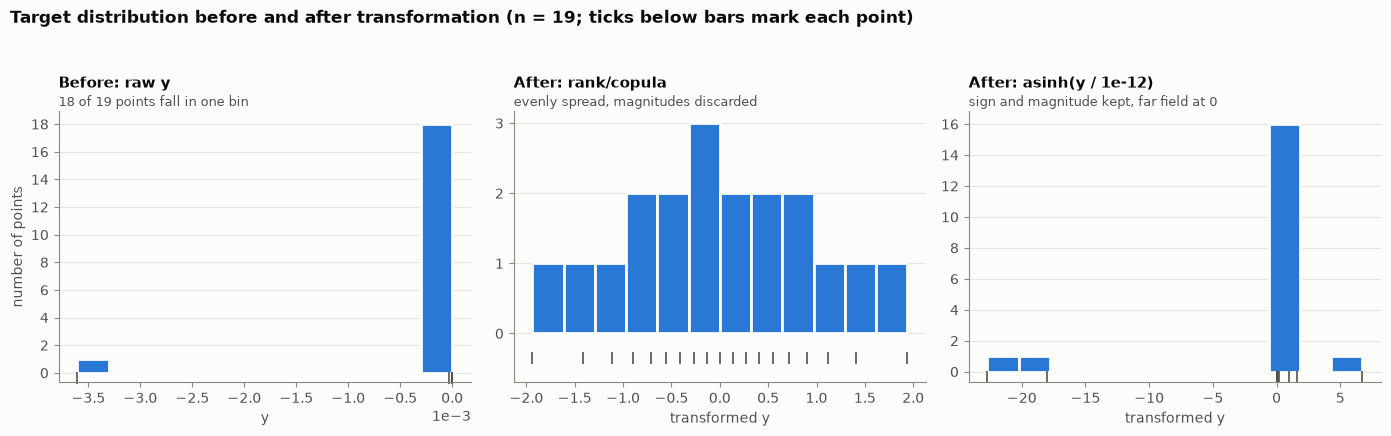

In [ ]:
# ------------------------------------------------ 
# Fig1. distribution before / after
# ------------------------------------------------
copula = norm.ppf((rankdata(y) - 0.5) / n)
asinh = np.arcsinh(y / 1e-12)
panels = [
    ("Before: raw y", "18 of 19 points fall in one bin", y, "y"),
    ("After: rank/copula", "evenly spread, magnitudes discarded", copula, "transformed y"),
    ("After: asinh(y / 1e-12)", "sign and magnitude kept, far field at 0", asinh, "transformed y"),
]
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
for ax, (title, sub, v, xl) in zip(axes, panels):
    ax.hist(v, bins=12, color=BLUE, edgecolor=SURFACE, linewidth=2)
    ax.plot(v, np.full(n, -0.35), "|", color=INK2, markersize=9, markeredgewidth=1.2, clip_on=False)
    ax.set_title(f"{title}\n", pad=4)
    ax.text(0, 1.02, sub, transform=ax.transAxes, color=INK2, fontsize=9)
    ax.set_xlabel(xl)
    ax.set_ylim(bottom=-0.7)
    ax.grid(axis="x", visible=False)
    ax.yaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True))
axes[0].set_ylabel("number of points")
axes[0].ticklabel_format(style="sci", axis="x", scilimits=(0, 0))
fig.suptitle("Target distribution before and after transformation (n = 19; ticks below bars mark each point)",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.94))
fig.savefig("dist_before_after.png", dpi=140)


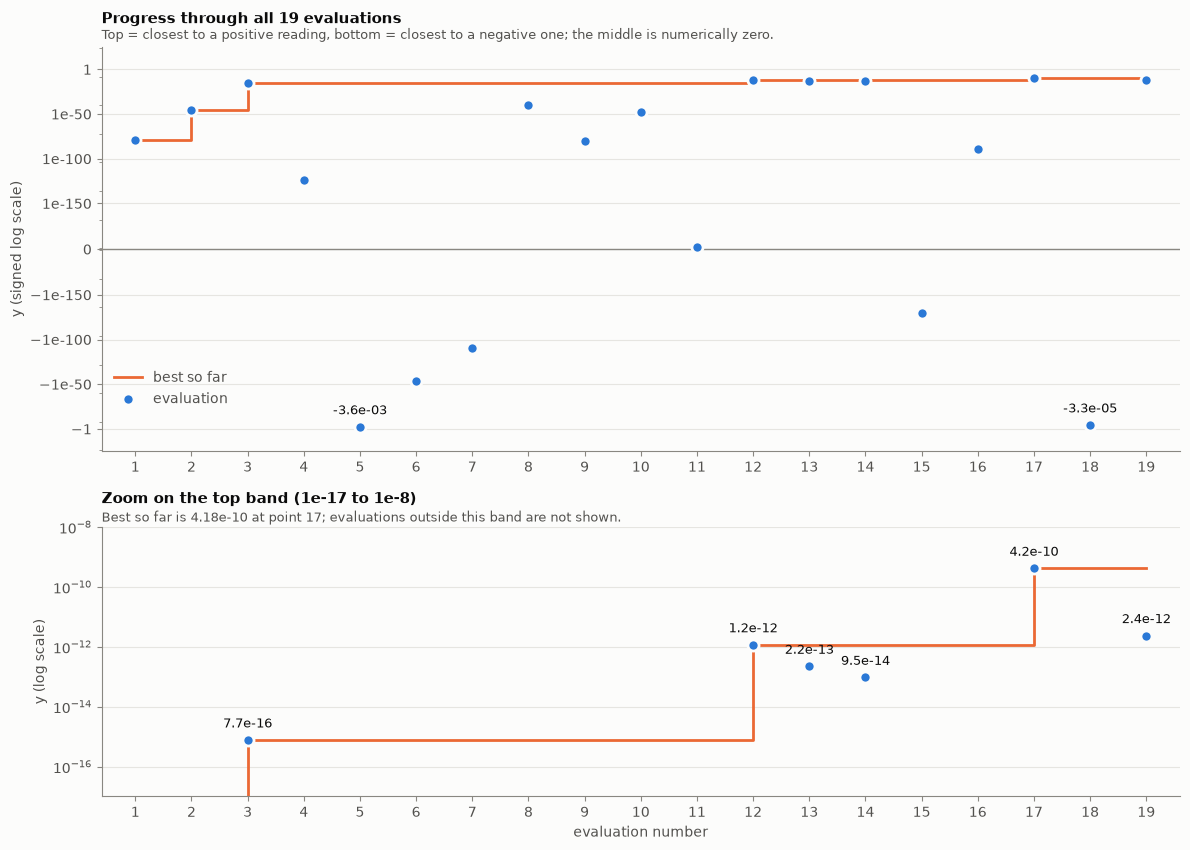

In [ ]:
# ------------------------------------------------ 
# Fig2. progress through all points
# ------------------------------------------------ 

best = np.maximum.accumulate(y)
inc = int(np.argmax(y))
fig, (ax, az) = plt.subplots(2, 1, figsize=(12, 8.6), height_ratios=[3, 2])
ax.axhline(0, color=MUTED, linewidth=1)
ax.step(idx, best, where="post", color=ORANGE, linewidth=2, label="best so far", zorder=2)
ax.scatter(idx, y, s=64, color=BLUE, edgecolor=SURFACE, linewidth=2, label="evaluation", zorder=3)
ax.set_yscale("symlog", linthresh=1e-200)
ticks = [-1e0, -1e-50, -1e-100, -1e-150, 0, 1e-150, 1e-100, 1e-50, 1e0]
ax.set_yticks(ticks)
ax.set_yticklabels(["−1", "−1e-50", "−1e-100", "−1e-150", "0", "1e-150", "1e-100", "1e-50", "1"])
ax.set_ylim(-1e25, 1e25)
ax.set_ylabel("y (signed log scale)")
for i in (4, 17):
    ax.annotate(f"{y[i]:.1e}", (idx[i], y[i]), xytext=(0, 9), textcoords="offset points",
                ha="center", fontsize=9, color=INK)
ax.legend(frameon=False, loc="lower left", bbox_to_anchor=(0.0, 0.08), labelcolor=INK2)
ax.set_title("Progress through all 19 evaluations\n", pad=4)
ax.text(0, 1.02, "Top = closest to a positive reading, bottom = closest to a negative one; "
        "the middle is numerically zero.", transform=ax.transAxes, color=INK2, fontsize=9)

lo, hi = 1e-17, 1e-8
m = (y > lo) & (y < hi)
az.step(idx, best, where="post", color=ORANGE, linewidth=2, zorder=2)
az.scatter(idx[m], y[m], s=64, color=BLUE, edgecolor=SURFACE, linewidth=2, zorder=3)
az.set_yscale("log")
az.set_ylim(lo, hi)
for i in np.where(m)[0]:
    az.annotate(f"{y[i]:.1e}", (idx[i], y[i]), xytext=(0, 9), textcoords="offset points",
                ha="center", fontsize=9, color=INK)
az.set_ylabel("y (log scale)")
az.set_xlabel("evaluation number")
az.set_title("Zoom on the top band (1e-17 to 1e-8)\n", pad=4)
az.text(0, 1.02, f"Best so far is {y[inc]:.2e} at point {inc + 1}; evaluations outside this band are not shown.",
        transform=az.transAxes, color=INK2, fontsize=9)
for a_ in (ax, az):
    a_.set_xticks(idx)
    a_.set_xlim(0.4, n + 0.6)
    a_.grid(axis="x", visible=False)
fig.tight_layout()
